In [1]:
""" Importing required modules """
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
np.random.seed(0)

In [2]:
""" Initialization of required parameters which have constant values """
N = 5000                                 # Population size
T = 300                                 # Time interval 
NN = np.arange(0, N)                      # Population size in array format (for plotting purposes)
TT = np.arange(0, T)                      # Time interval in array format (for plotting purposes)
SCE_50 = 20                               # A constant level of exposure that ensures subclinical exposure induced immunity with a probability 0.5. 
I_mf = 200                                # A constant increment in immunity whenever a person is cured of infection. (Units = EU)
P_r = 0.2                                 # Probability that an infected individual is cured  
I_sce = 20                                # A constant level of exposure that ensures subclinical exposure induced immunity with a probability 0.5. (Units = EU)
I_d = 2                                   # A small decrement by which immunity decreases every time unit if not exposed or infected. (Units = Eu)
I_c = 40                                  # Constant Immunity increase due to cross-immunity
a = 2                                     # Parameter deciding the sharpness of the sigmoid relationship 
r = 1.0                    # Restriction parameter
ci = 0.05*r                               # Cross immunity parameter

In [3]:
# Creating empty 2D array of P values. This array would represent the modified probability of infection for each individual with respect to time.
Pone = np.zeros((N, T))
# Creating empty 2D array of P values. This array would represent the modified probability of infection for each individual with respect to time.
Ptwo = np.zeros((N, T))
# Creating empty 2D array of P_inf(i,t) values. This array would represent the probability of infection for each individual with respect to time.
P_inf = np.zeros((N, T))
# Creating zeros 2D array of P_sce(i,t) values. This array would represent the probability of sub-clinical exposure for each individual with respect to time.
P_sce = np.empty((N, T))
# Creating 2D array of ID_50(i,t) values and assigning values from the standard normal distribution. This array would represent the time evolution of the immunity of each of the individuals with respect to time.
ID_50 = np.zeros((N, 1))                              
# Creating array of E(i,0) values and assigning values from the normal distribution with mean = 70, sd = 30 (for t = 0 case). This array represents the expose bias of each of the individuals at initial time.
E = np.zeros((N, 1))
# Creating array of S(i,t) values. These are the infective states of the individuals with respect to time.
S = np.zeros((N, 1))
# Creating Array which will show the time evolution of I (Total infective state of the population)  
I = np.zeros((T,1))   

for j in range(N):
    x1 = np.random.choice(np.arange(0, 2), p=[0.95, 0.05])
    S[j, 0] = x1  
    x2 = round(np.random.normal(1, 8), 3)
    if (x2 < 0):
        x2 = 0.0001
        E[j, 0] = x2 * r
    else: 
        E[j, 0] = x2 * r
    x3 = round(np.random.normal(100, 10), 3)
    if (x3 < 0):
        x3 = 0.0001
        ID_50[j, 0] = x3
    else:
        ID_50[j, 0] = x3
    
print('Top to bottom - Individuals (0 to N) \nLeft to right - Time steps (0 to T) \nFirst column contains the values for T = 0 \n')
print("1. Initial State of the individuals in the population -- S(i,0):")
print(S)
print("\n 2. Initial expose bias of the individuals in the population -- E(i,0):")
print(E)
print("\n 3. Initial distribution of population immunity levels -- ID_50(i,0):")
print(ID_50)

Top to bottom - Individuals (0 to N) 
Left to right - Time steps (0 to T) 
First column contains the values for T = 0 

1. Initial State of the individuals in the population -- S(i,0):
[[0.]
 [0.]
 [0.]
 ...
 [1.]
 [0.]
 [1.]]

 2. Initial expose bias of the individuals in the population -- E(i,0):
[[6.9330e+00]
 [1.5940e+01]
 [1.1129e+01]
 ...
 [1.0000e-04]
 [1.0000e-04]
 [1.0000e-04]]

 3. Initial distribution of population immunity levels -- ID_50(i,0):
[[115.529]
 [ 90.227]
 [ 94.941]
 ...
 [ 96.571]
 [103.2  ]
 [ 98.509]]


In [4]:
for t in range(T):
		P_inf_temp = np.zeros((N,))
		P_sce_temp = np.zeros((N,))
		P1_temp = np.zeros((N,))
		P2_temp = np.zeros((N,))
		S_temp = np.zeros((N, 1))
		ID_50_temp = np.zeros((N, 1))
		I_trans_temp = np.zeros((N, 1))
		I[t] = np.sum(S[:,-1])
		for n in range(N):
			I_trans_temp[n] = (30 * I[t] * r)/(250 + I[t])
			P_inf_temp[n] = (E[n][0])**a / ((ID_50[n][-1]**a) + (E[n][0]**a))
			P1_temp[n] = 1-((1-P_inf_temp[n])**(I_trans_temp[n]))
			P_sce_temp[n] = (E[n][0])**a / ((SCE_50)**a + (E[n][0])**a)
			P2_temp[n] = 1-((1-P_sce_temp[n])**(I_trans_temp[n]))
			# Condition to be imposed when S(t) = 1
			if S[n][-1] == 1:
				x4 = round(np.random.random(), 3)
				if x4 < P_r:
					S_temp[n] = 0
					ID_50_temp[n] = ID_50[n][-1] + I_mf
				else:
					S_temp[n] = 1
					x5 = round(np.random.random(), 3)
					if x5 < P1_temp[n]:
						S_temp[n] = 1
						ID_50_temp[n] = ID_50[n][-1]
					else:
						S_temp[n] = 0
						x6 = round(np.random.random(), 3)
						if x6 < P2_temp[n]:
							ID_50_temp[n] = ID_50[n][-1] + I_sce
						else:
							if (ID_50[n][-1] - I_d < 0):
								ID_50_temp[n] = 0
							else:
								ID_50_temp[n] = ID_50[n][-1] - I_d
			# Condition to be imposed when S(t) = 0
			else:
				x7 = round(np.random.random(), 3)
				if x7 < P1_temp[n]:
					S_temp[n] = 1
					ID_50_temp[n] = ID_50[n][-1]
				else:
					S_temp[n] = 0
					x8 = round(np.random.random(), 3)
					if x8 < P2_temp[n]:
						x9 = round(np.random.random(), 3)
						if x9 < ci:
							ID_50_temp[n] = ID_50[n][-1] + I_sce + I_c
						else:
							ID_50_temp[n] = ID_50[n][-1] + I_sce	
					else:
						x9 = round(np.random.random(), 3)
						if x9 < ci:
							if (ID_50[n][-1] - I_d - I_c < 0):
								ID_50_temp[n] = 0
							else:
								ID_50_temp[n] = ID_50[n][-1] - I_d + I_c
						else:
							if (ID_50[n][-1] - I_d < 0):
								ID_50_temp[n] = 0
							else:
								ID_50_temp[n] = ID_50[n][-1] - I_d
		ID_50 = np.hstack((ID_50, ID_50_temp))
		S = np.hstack((S, S_temp))
		P_inf[:,t] = P_inf_temp
		P_sce[:,t] = P_sce_temp
		Pone[:,t] = P1_temp
		Ptwo[:,t] = P2_temp
		print('\n')
		print("Infective state of the population:")
		print(I[t])
		print("Altered state of the population:")
		print(S)
print("\nOverall trend:")
print(I.reshape(1,T))
print("\nImmunity levels:")
print(ID_50)



Infective state of the population:
[249.]
Altered state of the population:
[[0. 0.]
 [0. 0.]
 [0. 1.]
 ...
 [1. 0.]
 [0. 0.]
 [1. 0.]]


Infective state of the population:
[245.]
Altered state of the population:
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 1. 0.]
 ...
 [1. 0. 0.]
 [0. 0. 0.]
 [1. 0. 0.]]


Infective state of the population:
[183.]
Altered state of the population:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 1. 0. 0.]
 ...
 [1. 0. 0. 0.]
 [0. 0. 0. 0.]
 [1. 0. 0. 0.]]


Infective state of the population:
[116.]
Altered state of the population:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 ...
 [1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]]


Infective state of the population:
[68.]
Altered state of the population:
[[0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0.]
 ...
 [1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]]


Infective state of the population:
[41.]
Altered state of the population:
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 1. 0.

In [5]:
print(P_inf.shape)
print(P_sce.shape)
print(S.shape)
print(ID_50.shape)
print(I.shape)

(5000, 300)
(5000, 300)
(5000, 301)
(5000, 301)
(300, 1)


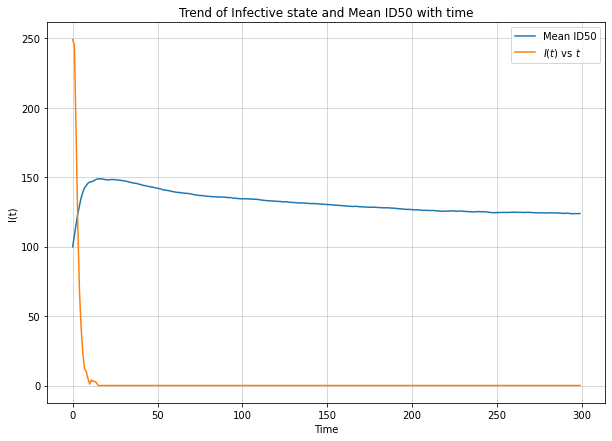

In [6]:
plt.figure(figsize=(10, 7))
X = np.zeros(T)
for t in range(T):
    x = np.mean(ID_50[:,t])
    X[t] = x
plt.plot(TT, X)
plt.plot(TT, I)
plt.title("Trend of Infective state and Mean ID50 with time")
plt.xlabel("Time")
plt.ylabel("I(t)")
plt.legend(["Mean ID50", "$I(t)$ vs $t$"])
plt.grid(linewidth=0.5)
plt.show()

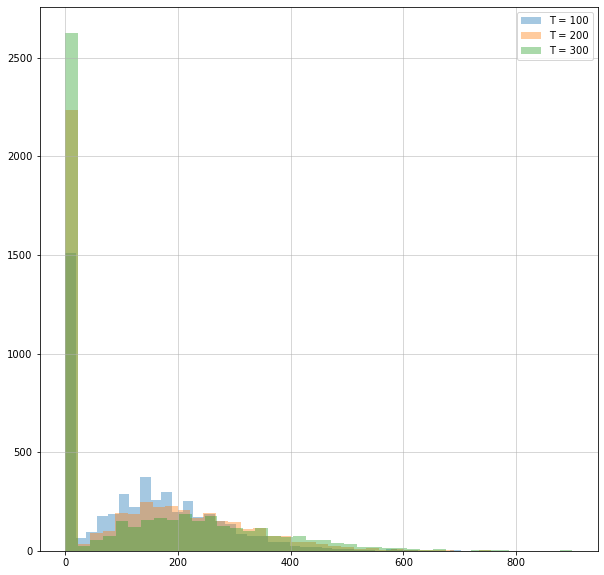

In [7]:
plt.figure(figsize=(10, 10))
plt.hist(ID_50[:, 100], bins=40, alpha=0.4)
plt.hist(ID_50[:, 200], bins=40, alpha=0.4)
plt.hist(ID_50[:, 300], bins=40, alpha=0.4)
plt.grid(linewidth=0.5)
plt.legend(["T = 100","T = 200","T = 300", ])
plt.show()

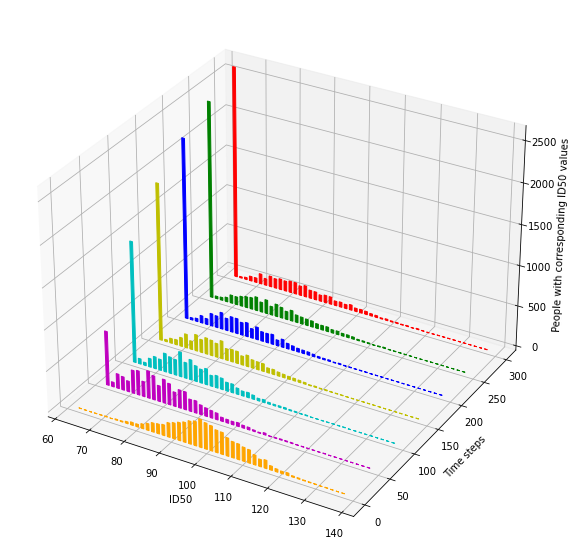

In [12]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
nbins = 50
for c, a in zip(['r', 'g', 'b', 'y', 'c', 'm', 'orange'], [300, 250, 200, 150, 100, 50, 0]):
    y = ID_50[:, a]
    hist, bins = np.histogram(y, bins=nbins)
    xs = (bins[:-1] + bins[1:])/2
    ax.bar(xs, hist, zs=a, zdir='y', color=c, ec=c, alpha=1.0)
ax.set_zlabel('People with corresponding ID50 values')
ax.set_ylabel('Time steps')
ax.set_xlabel('ID50')
plt.show()


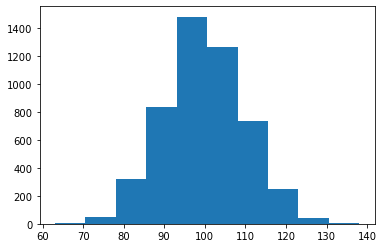

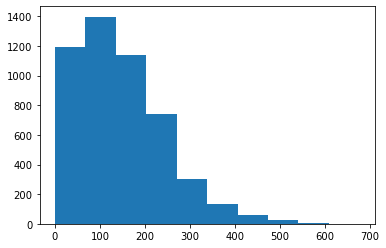

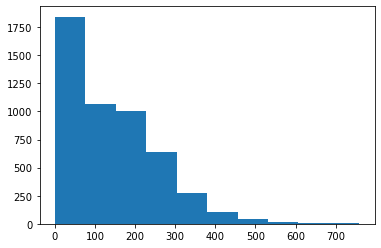

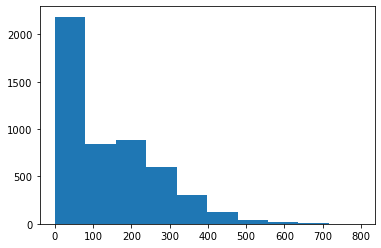

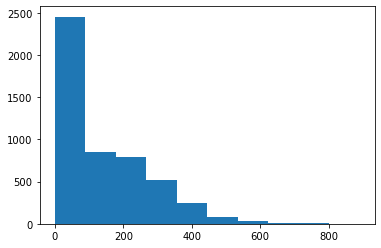

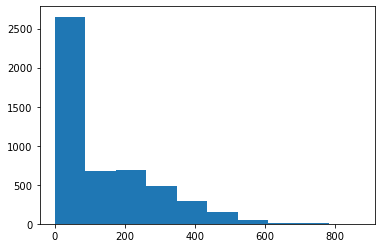

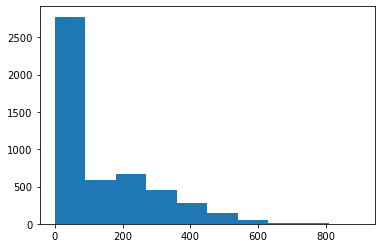

In [13]:
plt.hist(ID_50[:, 0])
plt.show()
plt.hist(ID_50[:, 50])
plt.show()
plt.hist(ID_50[:, 100])
plt.show()
plt.hist(ID_50[:, 150])
plt.show()
plt.hist(ID_50[:, 200])
plt.show()
plt.hist(ID_50[:, 250])
plt.show()
plt.hist(ID_50[:, 300])
plt.show()

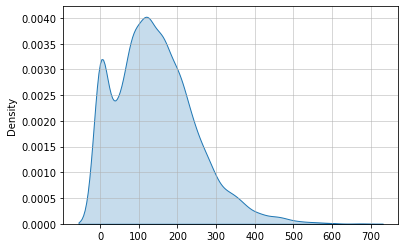

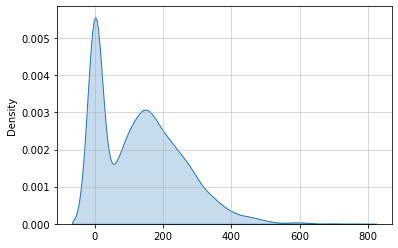

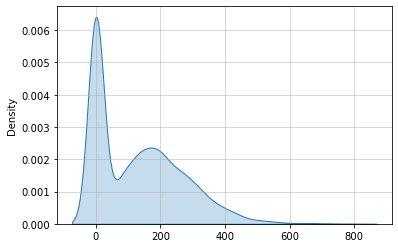

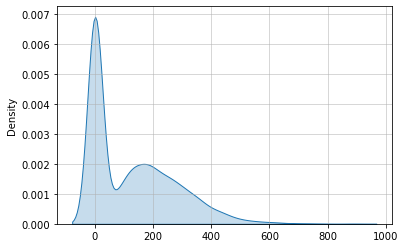

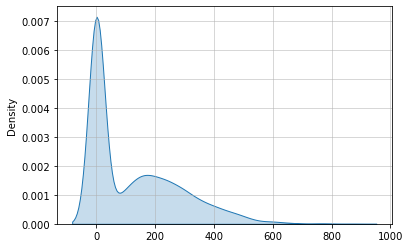

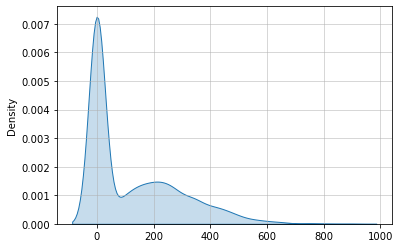

In [14]:
plt.figure()
sns.kdeplot(ID_50[:, 50], fill=True)
plt.grid(linewidth=0.5)
plt.show()
sns.kdeplot(ID_50[:, 100], fill=True)
plt.grid(linewidth=0.5)
plt.show()
sns.kdeplot(ID_50[:, 150], fill=True)
plt.grid(linewidth=0.5)
plt.show()
sns.kdeplot(ID_50[:, 200], fill=True)
plt.grid(linewidth=0.5)
plt.show()
sns.kdeplot(ID_50[:, 250], fill=True)
plt.grid(linewidth=0.5)
plt.show()
sns.kdeplot(ID_50[:, 300], fill=True)
plt.grid(linewidth=0.5)
plt.show()